# IRWA Final Project — Part 3: Ranking and Filtering

1. **Score:** we rank the AND matches with TF-IDF + cosine, BM25 and our own score.
2. **word2vec + cosine:** we rank them with word2vec and show the top 20 of our five test queries.
3. **Better representations than word2vec:** discussed in the report.

The code is in `irwa_ranking.py` (class `Ranker`, with `method="tfidf" | "bm25" | "ours" | "word2vec"`). We reuse the
Part 1 pre-processing, the Part 2 index and AND search, and the Part 2 metrics. After the Part 2 feedback, the test
queries are now called **Q1–Q5** and the validation queries **V1–V2**.

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from IPython.display import display

nltk.download("stopwords", quiet=True)

sys.path.append("../part_1")       # irwa_preprocessing.py (Part 1)
sys.path.append("../part_2")       # irwa_indexing.py, irwa_evaluation.py (Part 2)
import irwa_preprocessing as pp
import irwa_ranking as rk
import irwa_evaluation as ev

DATA = Path("../../data")
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
RESULTS = Path("results")          # CSV files with the results
RESULTS.mkdir(exist_ok=True)

pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 200)

# one fixed colour per method in every figure (validated colour-blind-safe categorical palette)
COLORS = {"tfidf": "#2a78d6", "bm25": "#eb6834", "ours": "#1baf7a", "word2vec": "#eda100"}
NAMES = {"tfidf": "TF-IDF + cosine", "bm25": "BM25", "ours": "Our score", "word2vec": "word2vec + cosine"}
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e3", "axes.axisbelow": True})

## 0. Data, queries and relevance labels

`test_queries_labels_all.csv` has a label for **every** AND match of Q1–Q5 (239 products): the 91 labels of Part 2 and
148 new ones, with the same criteria. This way every ranking is evaluated with complete labels. For V1–V2 we use the 20
labelled products of `validation_labels.csv`.

In [2]:
corpus = pd.read_pickle(DATA / "processed_corpus.pkl")
labels = pd.read_csv("test_queries_labels_all.csv")
val_labels = (pd.read_csv(DATA / "validation_labels.csv")
              .rename(columns={"labels": "is_relevant"})[["query_id", "pid", "is_relevant"]])

TEST_QUERIES = labels.groupby("query_id")["query"].first().to_dict()            # Q1-Q5
VAL_QUERIES = {1: "women full sleeve sweatshirt cotton", 2: "men slim jeans blue"}  # V1-V2

print(f"{len(corpus):,} products")
display(labels.groupby(["query_id", "query"]).agg(AND_matches=("pid", "size"), relevant=("is_relevant", "sum"),
                                                  new_in_part_3=("labelled_in", lambda s: (s == "part 3").sum())))

28,080 products


,,AND_matches,relevant,new_in_part_3
query_id,query,,,
1,men white formal shirt slim fit,25,9,5
2,women floral print shirt,35,27,15
3,women black track pants with zip pockets,11,8,0
4,women pure cotton t-shirt pack of 3,140,26,120
5,black running shoes for men,28,6,8


In [3]:
start = time.time()
ranker = rk.Ranker(corpus)
print(f"index and statistics built in {time.time() - start:.1f} s | {len(ranker.index):,} terms | "
      f"average length of all_terms: {ranker.avg_len:.1f} terms")

index and statistics built in 2.4 s | 6,343 terms | average length of all_terms: 43.9 terms


Helpers: the results of one method in the Part 2 evaluation format, and a short table with the top of a ranking.

In [4]:
def evaluation_input(method, queries, judgments):
    """Judged products returned by the AND search, in the order of the method (Part 2 format)."""
    rows = []
    for qid, query in queries.items():
        judged = judgments[judgments["query_id"] == qid].set_index("pid")["is_relevant"]
        for rank, (pid, score) in enumerate(ranker.search(query, method), start=1):
            if pid in judged.index:
                rows.append({"query_id": qid, "pid": pid, "rank": rank,
                             "predicted_relevance": score, "is_relevant": int(judged[pid])})
    return pd.DataFrame(rows)


def show_top(query, method, k=10, judgments=labels, qid=None):
    """Top-k of a method with the relevance label of each product."""
    table = rk.results_table(ranker, ranker.search(query, method, top_k=k))
    if qid is not None:
        judged = judgments[judgments["query_id"] == qid].set_index("pid")["is_relevant"]
        table.insert(2, "relevant", table["pid"].map(judged))
    return table

---
# 1. Score

## 1a. TF-IDF + cosine similarity

$w(t,d) = tf(t,d) \cdot \log(N/df_t)$, where $tf$ is the number of times the term appears, and
$\cos(q,d) = \frac{q \cdot d}{|q|\,|d|}$. $|d|$ is the length of the TF-IDF vector of the **whole** product (all its
terms), so the score is a real cosine. The $tf$ of the labs ($count / \lVert counts \rVert$) gives exactly the same
cosine, because this division is the same for all the terms of a product and the cosine already divides by the length
of the vector.

In [5]:
display(show_top(TEST_QUERIES[1], "tfidf", qid=1))

,pid,score,relevant,title,brand_full,average_rating_num,discount_pct,in_stock
rank,,,,,,,,
1,SHTF6VCHUQ8HKQPE,0.5807,0,Men Slim Fit Solid Casual Shirt,jai textiles,3.4,72.0,True
2,SHTFEBYMF9RTZYKG,0.5036,0,Men Slim Fit Solid Spread Collar Casual Shirt,purple state,2.9,77.0,True
3,SHTFEBYMGU47WWZG,0.5036,0,Men Slim Fit Solid Spread Collar Casual Shirt,purple state,2.9,77.0,True
4,SHTFEBYMHVXRHZCZ,0.5036,0,Men Slim Fit Solid Spread Collar Casual Shirt,purple state,1.0,75.0,True
5,SHTFDYRQRYGTW4PX,0.4699,1,Men Slim Fit Printed Button Down Collar Formal Shirt,mods,3.7,46.0,True
6,SHTF98P8MTY7ZXAZ,0.3982,1,Men Slim Fit Solid Spread Collar Formal Shirt,dudlind,4.4,38.0,True
7,SHTFW52ZMBHJZPYP,0.3952,1,Men Slim Fit Printed Spread Collar Formal Shirt,truemoda,NaN,65.0,False
8,SHTFW52ZURHFKNTZ,0.3899,1,Men Slim Fit Printed Button Down Collar Formal Shirt,truemoda,4.2,62.0,True
9,SHTFDYMU7MCMFCT9,0.3724,0,Men Slim Fit Geometric Print Button Down Collar Casual S...,mods,3.6,46.0,True


## 1b. BM25

$$BM25(q,d) = \sum_{t \in q} \log\frac{N}{df_t} \cdot \frac{tf(t,d)\,(k_1+1)}{tf(t,d) + k_1\left(1-b+b\,\frac{|d|}{avgdl}\right)}$$

The idf is the same as in TF-IDF, and we use the usual values $k_1 = 1.2$ and $b = 0.75$.

In [6]:
display(show_top(TEST_QUERIES[2], "bm25", qid=2))

,pid,score,relevant,title,brand_full,average_rating_num,discount_pct,in_stock
rank,,,,,,,,
1,FABFZU9YG9FZGWCY,14.4313,0,Rayon Floral Print Shirt Fabric (Unstitched),vims raiyo,3.2,60.0,True
2,SHTFHQTAZZVYHZGY,14.4313,1,Women Slim Fit Floral Print Casual Shirt,sur,2.6,46.0,True
3,SHTFJZC45ZFYGSYH,14.4313,1,Women Slim Fit Floral Print Casual Shirt,sur,4.3,51.0,True
4,FABFZU8HREHCNJR5,14.3771,0,"Rayon Printed, Floral Print Shirt Fabric (Unstitched)",vims raiyo,3.2,60.0,True
5,FABFZ3HZ7Y2N3M36,14.3191,0,Rayon Floral Print Shirt Fabric (Unstitched),vims raiyo,3.6,60.0,True
6,FABFZ5YRSXA2BPAY,14.3191,0,Rayon Floral Print Shirt Fabric (Unstitched),vims raiyo,3.2,77.0,True
7,FABFZFR2ETCKRZJE,14.3191,0,Cotton Floral Print Shirt Fabric (Unstitched),vims raiyo,3.2,77.0,True
8,FABFZPYPKUBSP55Z,14.3191,0,Rayon Floral Print Shirt Fabric (Unstitched),vims raiyo,3.2,60.0,True
9,FABFZU92QEBHMCZB,13.9928,0,"Rayon Floral Print, Self Design Shirt Fabric (Unstitched)",vims raiyo,3.2,60.0,True


**Effect of $k_1$ and $b$** (mean NDCG@10 over Q1–Q5). We keep the standard values, because choosing the best cell
would over-fit our five queries (it would work well on them, but not necessarily on other queries).

b,0.000,0.250,0.500,0.750,1.000
k1,,,,,
0.500,0.493,0.683,0.647,0.626,0.540
1.200,0.473,0.661,0.607,0.605,0.514
2.000,0.473,0.602,0.600,0.618,0.527
3.000,0.473,0.574,0.589,0.603,0.538


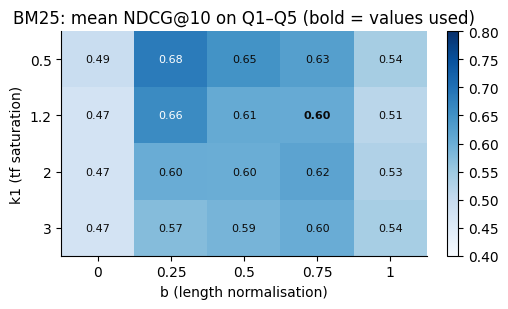

In [7]:
grid_k1, grid_b = [0.5, 1.2, 2.0, 3.0], [0.0, 0.25, 0.5, 0.75, 1.0]
grid = pd.DataFrame(index=grid_k1, columns=grid_b, dtype=float)
for k1 in grid_k1:
    for b in grid_b:
        ranker.k1, ranker.b = k1, b
        res = evaluation_input("bm25", TEST_QUERIES, labels)
        grid.loc[k1, b] = ev.mean_ndcg_at_k(res, 10, judgments=labels)[0]
ranker.k1, ranker.b = rk.BM25_K1, rk.BM25_B   # back to the standard values
grid.index.name, grid.columns.name = "k1", "b"
with pd.option_context("display.float_format", "{:.3f}".format):
    display(grid)

fig, ax = plt.subplots(figsize=(5.2, 3.2))
im = ax.imshow(grid.values.astype(float), cmap="Blues", vmin=0.4, vmax=0.8, aspect="auto")
ax.set_xticks(range(len(grid_b)), [f"{b:g}" for b in grid_b]); ax.set_yticks(range(len(grid_k1)), [f"{k:g}" for k in grid_k1])
ax.set_xlabel("b (length normalisation)"); ax.set_ylabel("k1 (tf saturation)"); ax.grid(False)
for i in range(len(grid_k1)):
    for j in range(len(grid_b)):
        v = grid.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v > 0.65 else "#0b0b0b",
                fontweight="bold" if (grid_k1[i], grid_b[j]) == (1.2, 0.75) else "normal")
ax.set_title("BM25: mean NDCG@10 on Q1–Q5 (bold = values used)")
fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout(); fig.savefig(FIGURES / "bm25_parameters.png", dpi=200); plt.show()

## 1c. How TF-IDF and BM25 differ

1. **Repeated terms:** with TF-IDF every repetition counts the same; with BM25 the extra repetitions count less and less
   (left figure).
2. **Length normalisation:** TF-IDF divides by the length of the whole TF-IDF vector (so it depends on the number of
   terms *and* on how rare they are); BM25 only uses the number of terms compared with the average, softened by $b$.

In the scatter plots each point is an AND match: $x$ is its position with TF-IDF and $y$ its position with BM25.
Points far from the diagonal are the products where the two rankings disagree.

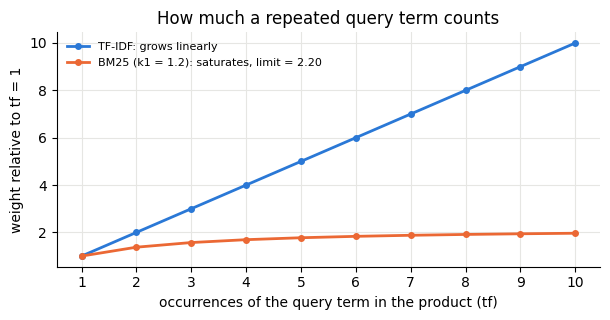

In [8]:
tf = np.arange(1, 11)
k1 = rk.BM25_K1
bm25_avg = tf * (k1 + 1) / (tf + k1)            # BM25 weight of a product of average length
fig, ax = plt.subplots(figsize=(6.2, 3.3))
ax.plot(tf, tf, color=COLORS["tfidf"], lw=2, marker="o", ms=4, label="TF-IDF: grows linearly")
ax.plot(tf, bm25_avg / bm25_avg[0], color=COLORS["bm25"], lw=2, marker="o", ms=4,
        label=f"BM25 (k1 = {k1}): saturates, limit = {(k1 + 1) / bm25_avg[0]:.2f}")
ax.set_xlabel("occurrences of the query term in the product (tf)")
ax.set_ylabel("weight relative to tf = 1")
ax.set_xticks(tf)
ax.set_title("How much a repeated query term counts")
ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout(); fig.savefig(FIGURES / "tf_saturation.png", dpi=200); plt.show()

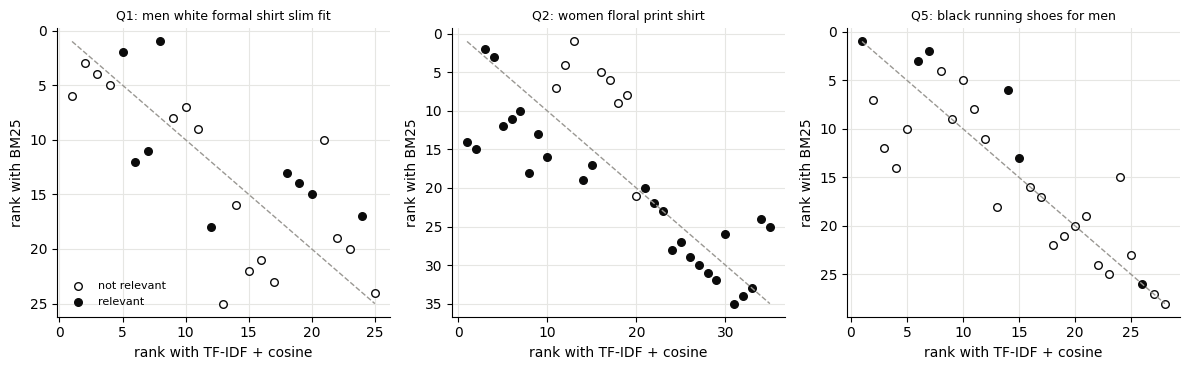

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, qid in zip(axes, [1, 2, 5]):
    rank_bm25 = {pid: r for r, (pid, _) in enumerate(ranker.search(TEST_QUERIES[qid], "bm25"), start=1)}
    judged = labels[labels["query_id"] == qid].set_index("pid")["is_relevant"]
    points = pd.DataFrame([(r, rank_bm25[pid], judged[pid])
                           for r, (pid, _) in enumerate(ranker.search(TEST_QUERIES[qid], "tfidf"), start=1)],
                          columns=["tfidf", "bm25", "relevant"])
    for rel, style in [(0, dict(facecolor="white", edgecolor="#0b0b0b", label="not relevant")),
                       (1, dict(color="#0b0b0b", label="relevant"))]:
        sel = points[points["relevant"] == rel]
        ax.scatter(sel["tfidf"], sel["bm25"], s=30, **style)
    n = len(points)
    ax.plot([1, n], [1, n], color="#9a9893", ls="--", lw=1)
    ax.set_xlabel("rank with TF-IDF + cosine"); ax.set_ylabel("rank with BM25")
    ax.set_title(f"Q{qid}: {TEST_QUERIES[qid]}", fontsize=9)
    ax.invert_yaxis()   # rank 1 at the top left
axes[0].legend(frameon=False, fontsize=8, loc="lower left")
fig.tight_layout(); fig.savefig(FIGURES / "tfidf_vs_bm25_ranks.png", dpi=200); plt.show()

In [10]:
def compare(qid, pids):
    """Rank with TF-IDF and BM25, length, TF-IDF norm and query-term occurrences of some products."""
    ranks = {m: {pid: r for r, (pid, _) in enumerate(ranker.search(TEST_QUERIES[qid], m), start=1)}
             for m in ("tfidf", "bm25")}
    terms = set(ranker.match(TEST_QUERIES[qid])[0])
    judged = labels[labels["query_id"] == qid].set_index("pid")["is_relevant"]
    return pd.DataFrame([{"title": ranker.corpus.at[pid, "title"], "relevant": judged[pid],
                          "rank TF-IDF": ranks["tfidf"][pid], "rank BM25": ranks["bm25"][pid],
                          "terms": ranker.doc_len[pid], "TF-IDF norm": round(ranker.doc_norm[pid], 1),
                          "query-term occurrences": sum(ranker.counts[pid][t] for t in terms)} for pid in pids])


# Q2: shirt fabric vs women's shirts (top 3 of BM25); Q1: top 2 of TF-IDF vs top 2 of BM25
display(compare(2, [p for p, _ in ranker.search(TEST_QUERIES[2], "bm25", top_k=3)]))
display(compare(1, [p for p, _ in ranker.search(TEST_QUERIES[1], "tfidf", top_k=2)]
                   + [p for p, _ in ranker.search(TEST_QUERIES[1], "bm25", top_k=2)]))

,title,relevant,rank TF-IDF,rank BM25,terms,TF-IDF norm,query-term occurrences
0,Rayon Floral Print Shirt Fabric (Unstitched),0,13,1,20,19.4,7
1,Women Slim Fit Floral Print Casual Shirt,1,3,2,20,14.0,7
2,Women Slim Fit Floral Print Casual Shirt,1,4,3,20,14.2,7


,title,relevant,rank TF-IDF,rank BM25,terms,TF-IDF norm,query-term occurrences
0,Men Slim Fit Solid Casual Shirt,0,1,6,25,12.1,10
1,Men Slim Fit Solid Spread Collar Casual Shirt,0,2,3,34,17.3,14
2,Men Slim Fit Printed Button Down Collar Formal Shirt,1,8,1,33,21.0,10
3,Men Slim Fit Printed Button Down Collar Formal Shirt,1,5,2,48,24.4,15


## 1d. Our score

$$\text{ours}(q,d) = BM25F(q,d) \times \Big(1 + w_{title}\,\frac{|q \cap title(d)|}{|q|}\Big) \times Q(d)$$

* **BM25F**: each field has a weight (title 3, details 2, brand 1, sub_category 0.5, description 0.5, from Part 1) and
  its own length normalisation, and we add the weighted counts *before* the saturation:
  $\tilde{tf} = \sum_f w_f \frac{tf_f}{1-b+b\,|d_f|/avg|d_f|}$, $BM25F = \sum_t idf(t)\,\frac{\tilde{tf}\,(k_1+1)}{\tilde{tf}+k_1}$.
* **Title factor** ($w_{title} = 1$): the score is multiplied by up to 2 when all the query terms are in the title,
  because the title says what the product *is*.
* **Quality factor** $Q(d) = \big(1 + 0.1\,\frac{rating-1}{4} + 0.05\,\frac{discount}{100}\big) \times (0.5$ if out of
  stock$)$. A missing rating gets the mean rating and a missing discount counts as 0.

In [11]:
q = pd.Series(ranker.quality)
in_stock = ranker.corpus["in_stock"].astype(bool).values
print(f"quality factor: in stock {q[in_stock].min():.3f}–{q[in_stock].max():.3f}, "
      f"out of stock {q[~in_stock].min():.3f}–{q[~in_stock].max():.3f} ({(~in_stock).sum():,} products)")
display(show_top(TEST_QUERIES[1], "ours", qid=1))

quality factor: in stock 1.000–1.141, out of stock 0.510–0.569 (1,644 products)


,pid,score,relevant,title,brand_full,average_rating_num,discount_pct,in_stock
rank,,,,,,,,
1,SHTF98P8MTY7ZXAZ,33.6871,1,Men Slim Fit Solid Spread Collar Formal Shirt,dudlind,4.4,38.0,True
2,SHTFDYRQRYGTW4PX,32.1821,1,Men Slim Fit Printed Button Down Collar Formal Shirt,mods,3.7,46.0,True
3,SHTFW52ZURHFKNTZ,32.1391,1,Men Slim Fit Printed Button Down Collar Formal Shirt,truemoda,4.2,62.0,True
4,SHTFFV8VHAH8N6Q9,31.6621,1,Men Slim Fit Striped Formal Shirt,dudlind,2.9,20.0,True
5,SHTFU73NHNAFBCCZ,30.6110,1,Men Slim Fit Solid Spread Collar Formal Shirt,solid styles,3.7,60.0,True
6,SHTFU73NTX6N3R63,30.6110,1,Men Slim Fit Solid Spread Collar Formal Shirt,solid styles,3.7,60.0,True
7,SHTFFV8VF99RZCW3,30.6072,0,Men Slim Fit Solid Formal Shirt,dudlind,2.9,20.0,True
8,SHTFU73NP63MDZZP,30.5831,1,Men Slim Fit Solid Spread Collar Formal Shirt,solid styles,3.7,58.0,True
9,SHTFZJFAGYVPQFCU,29.6749,1,Men Slim Fit Striped Spread Collar Formal Shirt,bonneville,NaN,58.0,True


**Ablation.** We add the parts of our score one by one (mean over Q1–Q5), and we check the effect of $w_{title}$.

In [12]:
def ablation_input(score):
    """Evaluation input (all Q1-Q5 matches are judged) for a score function f(terms, docs) -> [(pid, score)]."""
    rows = []
    for qid, query in TEST_QUERIES.items():
        terms, docs = ranker.match(query)
        judged = labels[labels["query_id"] == qid].set_index("pid")["is_relevant"]
        for rank, (pid, s) in enumerate(rk._sort(score(terms, docs)), start=1):
            rows.append({"query_id": qid, "pid": pid, "rank": rank, "predicted_relevance": s,
                         "is_relevant": int(judged[pid])})
    return pd.DataFrame(rows)


VARIANTS = {
    "BM25": ranker.score_bm25,
    "BM25F": ranker.score_bm25f,
    "BM25F x title": lambda t, d: [(p, s * ranker.title_factor(t, p)) for p, s in ranker.score_bm25f(t, d)],
    "BM25F x title x quality (our score)": ranker.score_ours,
}
ablation = {}
for variant, score in VARIANTS.items():
    t = ev.evaluate(ablation_input(score), ks=(10,), judgments=labels)
    ablation[variant] = t.loc["mean", [("P", 10), ("AP", 10), ("NDCG", 10)]]
ablation = pd.DataFrame(ablation).T
ablation.columns = ["P@10", "MAP@10", "NDCG@10"]
with pd.option_context("display.float_format", "{:.3f}".format):
    display(ablation)
ablation.to_csv(RESULTS / "ablation.csv", float_format="%.3f")

title_weights = {}
for w in [0.5, 1, 2]:
    ranker.title_weight = w
    title_weights[w] = ev.mean_ndcg_at_k(ablation_input(ranker.score_ours), 10, judgments=labels)[0]
ranker.title_weight = rk.TITLE_WEIGHT   # back to the value we use
print("mean NDCG@10 of our score with w_title =", {w: round(v, 3) for w, v in title_weights.items()})

,P@10,MAP@10,NDCG@10
BM25,0.460,0.793,0.605
BM25F,0.580,0.788,0.729
BM25F x title,0.740,0.903,0.885
BM25F x title x quality (our score),0.740,0.915,0.890


mean NDCG@10 of our score with w_title = {0.5: np.float64(0.889), 1: np.float64(0.89), 2: np.float64(0.89)}


---
# 2. word2vec + cosine similarity

We train word2vec (gensim, skip-gram, 100 dimensions, window 5, words seen at least twice, 10 epochs) on **our own
corpus**: each title, details and description is one sentence of Part 1 terms, so every query term has a vector (a
pre-trained model would not know `tshirt` or `sleev`). With one worker and a fixed seed we get the same vectors on every
run. A product is the **average of the vectors of its `all_terms`**, a query is the average of the vectors of its terms,
and the score is the cosine between them.

In [13]:
start = time.time()
ranker.train_word2vec()
print(f"word2vec trained in {time.time() - start:.0f} s | vocabulary: {len(ranker.w2v.wv):,} terms")
similar = {w: ", ".join(f"{s} ({v:.2f})" for s, v in ranker.w2v.wv.most_similar(w, topn=5))
           for w in ["slim", "formal", "floral", "zip", "run"]}
display(pd.Series(similar, name="most similar terms").to_frame())

word2vec trained in 25 s | vocabulary: 4,540 terms


,most similar terms
slim,"regular (0.67), powder (0.64), wingtip (0.62), punto (0...."
formal,"ceremoni (0.53), thatã (0.48), client (0.48), blazer (0...."
floral,"paisley (0.67), checker (0.66), sanganeri (0.65), wingti..."
zip,"closur (0.63), stopper (0.62), plenti (0.60), packabl (0..."
run,"jaquard (0.64), gyme (0.63), ignit (0.62), circuit (0.61..."


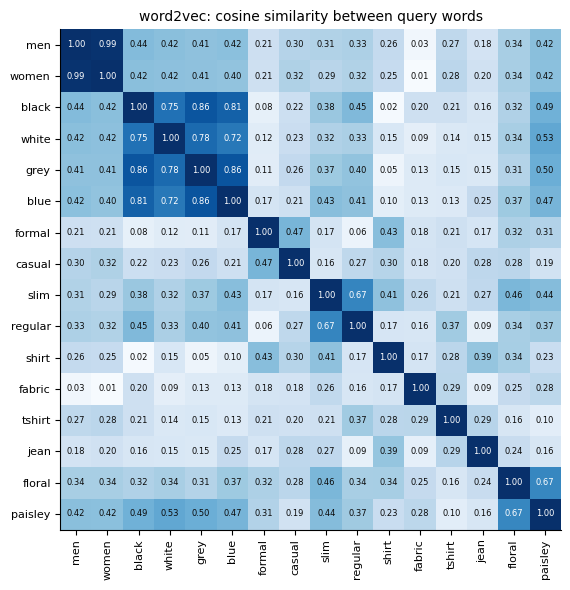

In [14]:
words = ["men", "women", "black", "white", "grey", "blue", "formal", "casual", "slim", "regular",
         "shirt", "fabric", "tshirt", "jean", "floral", "paisley"]
stems = [pp.preprocess_text(w)[0] for w in words]
vectors = ranker.w2v.wv[stems]
vectors = vectors / np.linalg.norm(vectors, axis=1, keepdims=True)
similarity = vectors @ vectors.T
fig, ax = plt.subplots(figsize=(7.2, 6))
ax.imshow(similarity, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(stems)), stems, rotation=90, fontsize=8)
ax.set_yticks(range(len(stems)), stems, fontsize=8); ax.grid(False)
for i in range(len(stems)):
    for j in range(len(stems)):
        ax.text(j, i, f"{similarity[i, j]:.2f}", ha="center", va="center", fontsize=6,
                color="white" if similarity[i, j] > 0.65 else "#0b0b0b")
ax.set_title("word2vec: cosine similarity between query words", fontsize=10)
fig.tight_layout(); fig.savefig(FIGURES / "word2vec_similarity.png", dpi=200); plt.show()

### Top 20 of each test query (word2vec + cosine)

`relevant` is our label. The five lists are also saved in `results/word2vec_top20.csv`.

In [15]:
w2v_lists = []
for qid, query in TEST_QUERIES.items():
    print(f"Q{qid}: {query}")
    top = show_top(query, "word2vec", k=20, qid=qid)
    display(top[["pid", "relevant", "score", "title"]])
    w2v_lists.append(top.reset_index().assign(query_id=qid, query=query))
w2v_lists = (pd.concat(w2v_lists)[["query_id", "query", "rank", "pid", "score", "relevant", "title"]]
             .rename(columns={"relevant": "is_relevant"}))
w2v_lists.to_csv("results/word2vec_top20.csv", index=False)

Q1: men white formal shirt slim fit


,pid,relevant,score,title
rank,,,,
1,SHTF6VCHUQ8HKQPE,0,0.9030,Men Slim Fit Solid Casual Shirt
2,SHTFEBYMF9RTZYKG,0,0.9027,Men Slim Fit Solid Spread Collar Casual Shirt
3,SHTFEBYMGU47WWZG,0,0.9027,Men Slim Fit Solid Spread Collar Casual Shirt
4,SHTFEBYMHVXRHZCZ,0,0.9027,Men Slim Fit Solid Spread Collar Casual Shirt
5,SHTFDYRQRYGTW4PX,1,0.8667,Men Slim Fit Printed Button Down Collar Formal Shirt
6,SHTFDYTZGHNN2JQ9,0,0.8610,Men Slim Fit Polka Print Button Down Collar Casual Shirt
7,SHTFW52ZURHFKNTZ,1,0.8606,Men Slim Fit Printed Button Down Collar Formal Shirt
8,SHTFDYMU7MCMFCT9,0,0.8565,Men Slim Fit Geometric Print Button Down Collar Casual S...
9,SHTFW52ZMFEJNWYY,0,0.8519,Men Slim Fit Printed Club Collar Casual Shirt


Q2: women floral print shirt


,pid,relevant,score,title
rank,,,,
1,SHTFHQTAZZVYHZGY,1,0.8942,Women Slim Fit Floral Print Casual Shirt
2,SHTFJZC45ZFYGSYH,1,0.8902,Women Slim Fit Floral Print Casual Shirt
3,SHTFSYG8TVBV8SUK,1,0.8623,Women Slim Fit Floral Print Casual Shirt
4,SHTFTGV4HRGGY4Z7,1,0.8569,Women Regular Fit Floral Print Button Down Collar Casual...
5,SHTFTGV4ATUQYVWY,1,0.8553,Women Regular Fit Floral Print Button Down Collar Casual...
6,SHTFS6YAFFX5XFFH,1,0.8545,Women Slim Fit Floral Print Casual Shirt
7,SHTFTGV4UGTG5HZH,1,0.8540,Women Regular Fit Floral Print Button Down Collar Casual...
8,SHTFWD49GF2EA3UN,1,0.8435,Women Slim Fit Printed Slim Collar Casual Shirt
9,SHTFMRH8WRCFQMYF,1,0.8345,Women Slim Fit Floral Print Spread Collar Casual Shirt


Q3: women black track pants with zip pockets


,pid,relevant,score,title
rank,,,,
1,TKPFK5KGEUPYCAUH,0,0.8425,Solid Men Black Track Pants
2,TKPFDT6GHGEYDTAS,1,0.8199,Solid Women Black Track Pants
3,TKPFKFZFXZT5XQYZ,1,0.7980,"Solid Women Black, Grey Track Pants"
4,TKPFUBDB8WGRDDYJ,1,0.7959,Solid Women Black Track Pants
5,TKPFWGMH448EGQTF,1,0.7953,Solid Women Black Track Pants
6,TKPFKFK4ESGQ95CK,1,0.7861,Solid Women Black Track Pants
7,TKPFRAHGFDFBHZ3J,1,0.7767,Solid Women Black Track Pants
8,TKSF5WHGCR4JBXYZ,0,0.7721,Regular Fit Women Black Cotton Lycra Blend Trousers
9,TKPFDGYPBYPAZNXH,1,0.7611,Self Design Women Black Track Pants


Q4: women pure cotton t-shirt pack of 3


,pid,relevant,score,title
rank,,,,
1,TSHFWAWKMVHVWC5P,0,0.8338,Solid Women Round Neck Multicolor T-Shirt (Pack of 5)
2,TSHFWBWEXX3N9FHZ,1,0.8319,"Solid Women Round Neck Blue, Maroon T-Shirt (Pack of 3)"
3,TSHFWAWKHFZDGSVX,0,0.8319,Solid Women Round Neck Multicolor T-Shirt (Pack of 5)
4,TSHFWBWEV3J285KG,1,0.8316,Solid Women Round Neck Blue T-Shirt (Pack of 3)
5,TSHFWBWERWBHYYJG,1,0.8313,Solid Women Round Neck Grey T-Shirt (Pack of 3)
6,TSHFWBWECMBZ9D8A,1,0.8312,Solid Women Round Neck Black T-Shirt (Pack of 3)
7,TSHFWAWKK2GNAQJA,0,0.8308,Solid Women Round Neck Maroon T-Shirt (Pack of 5)
8,TSHFWBWEGZEDCABK,1,0.8308,Solid Women Round Neck Maroon T-Shirt (Pack of 3)
9,TSHFWAWKKGYZSNHU,0,0.8300,Solid Women Round Neck Grey T-Shirt (Pack of 5)


Q5: black running shoes for men


,pid,relevant,score,title
rank,,,,
1,SHOEKNRJ34UCMAPA,1,0.9045,"SPRINT Running Shoes For Men (Black, Grey)"
2,SHOFN3EJHXHGSGUC,1,0.8818,RS-7250 Running Shoes For Men (Black)
3,SHOFTZFQP8W9G86F,0,0.7961,Running Shoes For Women (Black)
4,SHOFTZFPNCU4VWHK,1,0.7959,Running Shoes For Men (Black)
5,SHOFKH9ZNNNWCHGC,0,0.7618,Running Shoes For Men (Blue)
6,SHOFZP2FHH8Z6ZHC,0,0.7547,Running Shoes For Women (Black)
7,SHOFRCTVKE4P38CH,0,0.7527,"Target Full Spike Cricket Shoes For Men (White, Black)"
8,SHOFVXG5XR59AFTH,0,0.7426,Lace Up For Men (Black)
9,SHOFVJX2TP8FRR7P,0,0.7395,Lace Up For Men (Black)


---
# 3. Comparison of the four rankings

## 3.1 Metrics ($K$ = 5, 10, 20)

We use the Part 2 metrics and rules (relevant products that AND does not return still count in R@K, F1@K and the ideal
NDCG). All the matches of Q1–Q5 are labelled; V1–V2 have 20 labelled products each.

In [16]:
tables = {"test": {}, "validation": {}}
for method in rk.METHODS:
    tables["test"][method] = ev.evaluate(evaluation_input(method, TEST_QUERIES, labels), ks=(5, 10, 20), judgments=labels)
    tables["validation"][method] = ev.evaluate(evaluation_input(method, VAL_QUERIES, val_labels), ks=(5, 10, 20),
                                               judgments=val_labels)

def summary(which):
    out = {NAMES[m]: t.loc["mean"] for m, t in tables[which].items()}
    out = pd.DataFrame(out).T
    out.columns = [f"{metric}@{k}" for metric, k in out.columns]
    return out[[f"{m}@{k}" for k in (5, 10, 20) for m in ("P", "R", "AP", "F1", "RR", "NDCG")]]

for which in ("test", "validation"):
    print(f"Mean over the {'test queries Q1-Q5' if which == 'test' else 'validation queries V1-V2'} "
          "(mean AP = MAP, mean RR = MRR)")
    with pd.option_context("display.float_format", "{:.3f}".format):
        display(summary(which))
    summary(which).to_csv(f"results/metrics_{which}.csv", float_format="%.3f")

per_query = pd.DataFrame({NAMES[m]: t[("NDCG", 10)].drop("mean") for m, t in tables["test"].items()})
per_query.index = [f"Q{q}" for q in per_query.index]
print("NDCG@10 per test query")
with pd.option_context("display.float_format", "{:.3f}".format):
    display(per_query)
per_query.to_csv("results/ndcg10_per_query.csv", float_format="%.3f")

Mean over the test queries Q1-Q5 (mean AP = MAP, mean RR = MRR)


,P@5,R@5,AP@5,F1@5,RR@5,NDCG@5,P@10,R@10,AP@10,F1@10,RR@10,NDCG@10,P@20,R@20,AP@20,F1@20,RR@20,NDCG@20
TF-IDF + cosine,0.480,0.200,0.670,0.263,0.680,0.491,0.580,0.494,0.628,0.490,0.680,0.617,0.390,0.679,0.608,0.456,0.680,0.631
BM25,0.560,0.282,0.847,0.353,0.900,0.626,0.460,0.446,0.793,0.419,0.900,0.605,0.440,0.732,0.672,0.504,0.900,0.730
Our score,0.920,0.463,0.940,0.580,1.000,0.923,0.740,0.690,0.915,0.660,1.000,0.890,0.480,0.773,0.895,0.540,1.000,0.859
word2vec + cosine,0.640,0.282,0.666,0.362,0.640,0.597,0.580,0.465,0.698,0.470,0.640,0.628,0.450,0.710,0.653,0.502,0.640,0.674


Mean over the validation queries V1-V2 (mean AP = MAP, mean RR = MRR)


,P@5,R@5,AP@5,F1@5,RR@5,NDCG@5,P@10,R@10,AP@10,F1@10,RR@10,NDCG@10,P@20,R@20,AP@20,F1@20,RR@20,NDCG@20
TF-IDF + cosine,0.900,0.392,1.000,0.544,1.000,0.934,0.800,0.685,0.974,0.735,1.000,0.858,0.475,0.800,0.951,0.594,1.000,0.852
BM25,1.000,0.442,1.000,0.611,1.000,1.000,0.800,0.685,0.988,0.735,1.000,0.861,0.475,0.800,0.973,0.594,1.000,0.858
Our score,1.000,0.442,1.000,0.611,1.000,1.000,0.750,0.646,0.983,0.691,1.000,0.828,0.475,0.800,0.963,0.594,1.000,0.855
word2vec + cosine,0.900,0.392,0.944,0.544,1.000,0.915,0.750,0.646,0.937,0.691,1.000,0.814,0.475,0.800,0.905,0.594,1.000,0.837


NDCG@10 per test query


,TF-IDF + cosine,BM25,Our score,word2vec + cosine
Q1,0.327,0.383,0.922,0.169
Q2,1.000,0.313,1.000,1.000
Q3,0.961,0.964,0.983,0.817
Q4,0.288,0.611,0.545,0.530
Q5,0.511,0.753,1.000,0.624


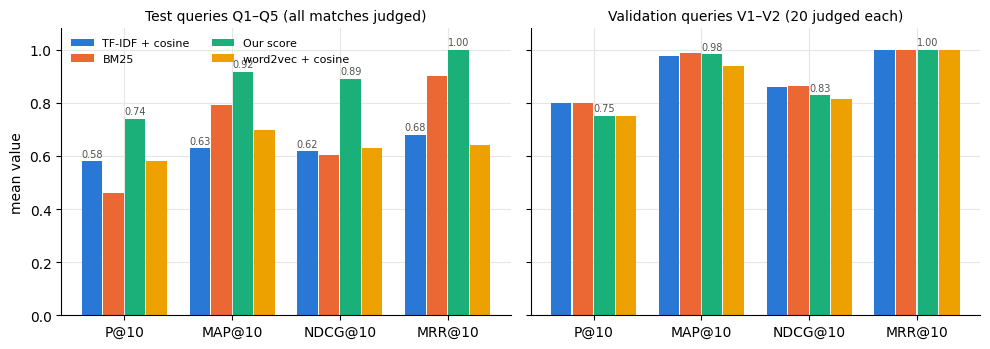

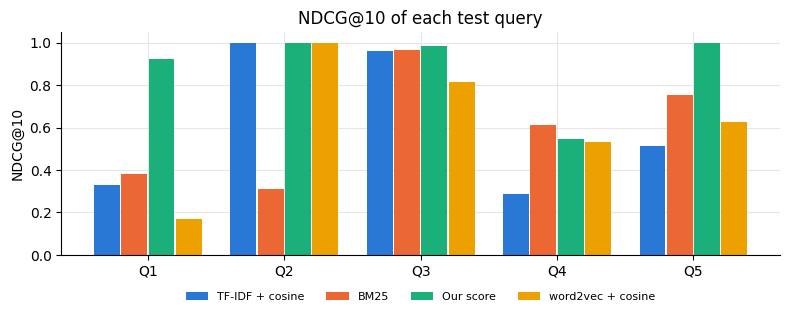

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
metrics = ["P@10", "AP@10", "NDCG@10", "RR@10"]
labels_x = ["P@10", "MAP@10", "NDCG@10", "MRR@10"]
for ax, which, title in [(axes[0], "test", "Test queries Q1–Q5 (all matches judged)"),
                         (axes[1], "validation", "Validation queries V1–V2 (20 judged each)")]:
    s = summary(which)
    width = 0.19
    for i, m in enumerate(rk.METHODS):
        vals = s.loc[NAMES[m], metrics].values.astype(float)
        bars = ax.bar(np.arange(len(metrics)) + (i - 1.5) * (width + 0.01), vals, width, color=COLORS[m],
                      label=NAMES[m])
        if m == "ours" or which == "test" and m == "tfidf":
            for x, v in zip(bars, vals):
                ax.text(x.get_x() + x.get_width() / 2, v + 0.01, f"{v:.2f}", ha="center", va="bottom", fontsize=7,
                        color="#52514e")
    ax.set_xticks(range(len(metrics)), labels_x); ax.set_ylim(0, 1.08); ax.set_title(title, fontsize=10)
axes[0].set_ylabel("mean value")
axes[0].legend(frameon=False, fontsize=8, ncol=2, loc="upper left")
fig.tight_layout(); fig.savefig(FIGURES / "metrics_by_method.png", dpi=200); plt.show()

fig, ax = plt.subplots(figsize=(8, 3.3))
width = 0.19
for i, m in enumerate(rk.METHODS):
    ax.bar(np.arange(len(per_query)) + (i - 1.5) * (width + 0.01), per_query[NAMES[m]], width, color=COLORS[m],
           label=NAMES[m])
ax.set_xticks(range(len(per_query)), per_query.index)
ax.set_ylim(0, 1.05); ax.set_ylabel("NDCG@10"); ax.set_title("NDCG@10 of each test query")
ax.legend(frameon=False, fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12))
fig.tight_layout(); fig.savefig(FIGURES / "ndcg_per_query.png", dpi=200); plt.show()

## 3.2 How different are the rankings?

Number of products that two methods have in common in their top 20 (mean over Q1–Q5; Q3 only has 11 matches).

,TF-IDF + cosine,BM25,Our score,word2vec + cosine
TF-IDF + cosine,18.2,15.8,13.4,13.6
BM25,15.8,18.2,13.4,14.2
Our score,13.4,13.4,18.2,12.8
word2vec + cosine,13.6,14.2,12.8,18.2


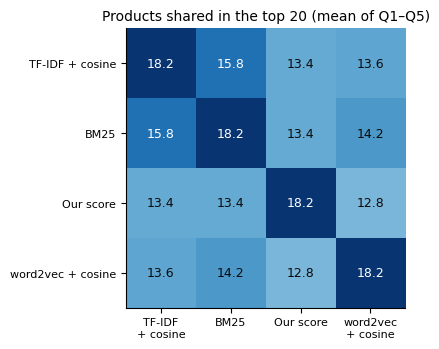

In [18]:
tops = {m: {qid: [p for p, _ in ranker.search(q, m, top_k=20)] for qid, q in TEST_QUERIES.items()} for m in rk.METHODS}
overlap = pd.DataFrame(index=[NAMES[m] for m in rk.METHODS], columns=[NAMES[m] for m in rk.METHODS], dtype=float)
for a in rk.METHODS:
    for b in rk.METHODS:
        overlap.loc[NAMES[a], NAMES[b]] = np.mean([len(set(tops[a][q]) & set(tops[b][q])) for q in TEST_QUERIES])
display(overlap.round(1))

fig, ax = plt.subplots(figsize=(4.8, 3.6))
im = ax.imshow(overlap.values.astype(float), cmap="Blues", vmin=8, vmax=18.4)
ax.set_xticks(range(4), [NAMES[m].replace(" + ", "\n+ ") for m in rk.METHODS], fontsize=8)
ax.set_yticks(range(4), [NAMES[m] for m in rk.METHODS], fontsize=8); ax.grid(False)
for i in range(4):
    for j in range(4):
        v = overlap.values[i, j]
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=9, color="white" if v > 15 else "#0b0b0b")
ax.set_title("Products shared in the top 20 (mean of Q1–Q5)", fontsize=10)
fig.tight_layout(); fig.savefig(FIGURES / "top20_overlap.png", dpi=200); plt.show()

rows = []
for m in rk.METHODS:
    for qid, query in TEST_QUERIES.items():
        for rank, (pid, score) in enumerate(ranker.search(query, m, top_k=20), start=1):
            rows.append({"method": m, "query_id": qid, "query": query, "rank": rank, "pid": pid, "score": score})
all_tops = pd.DataFrame(rows).merge(labels[["query_id", "pid", "is_relevant", "title"]], on=["query_id", "pid"])
all_tops.sort_values(["method", "query_id", "rank"]).to_csv("results/top20_all_methods.csv", index=False,
                                                            float_format="%.4f")

## 3.3 Examples: the top 5 of each method

In Q2, BM25 puts the short shirt fabrics first. In Q5, our score moves down the women's shoes, which only match `men`
because of the sub_category "Men's Footwear".

In [19]:
def short_title(title):
    """Shorter title for side-by-side tables: drop the most common words, keep the pack size."""
    for word in ("Solid ", "Round Neck ", "Button Down Collar ", "Spread Collar ", "Casual ", " (Unstitched)"):
        title = title.replace(word, "")
    return " ".join(title.split())[:44]


for qid in (2, 5, 4):
    print(f"Q{qid}: {TEST_QUERIES[qid]}")
    side = {}
    for m in rk.METHODS:
        top = show_top(TEST_QUERIES[qid], m, k=5, qid=qid)
        side[NAMES[m]] = [f"{'✓' if r else '✗'} {short_title(t)}" for r, t in zip(top["relevant"], top["title"])]
    display(pd.DataFrame(side, index=range(1, 6)))

Q2: women floral print shirt


,TF-IDF + cosine,BM25,Our score,word2vec + cosine
1,✓ Women Slim Fit Floral Print Shirt,✗ Rayon Floral Print Shirt Fabric (Unstitched),✓ Women Regular Fit Floral Print Shirt,✓ Women Slim Fit Floral Print Shirt
2,✓ Women Slim Fit Floral Print Shirt,✓ Women Slim Fit Floral Print Shirt,✓ Women Slim Fit Floral Print Shirt,✓ Women Slim Fit Floral Print Shirt
3,✓ Women Slim Fit Floral Print Shirt,✓ Women Slim Fit Floral Print Shirt,✓ Women Regular Fit Floral Print Shirt,✓ Women Slim Fit Floral Print Shirt
4,✓ Women Slim Fit Floral Print Shirt,"✗ Rayon Printed, Floral Print Shirt Fabric (Un",✓ Women Regular Fit Floral Print Shirt,✓ Women Regular Fit Floral Print Shirt
5,✓ Women Regular Fit Floral Print Shirt,✗ Rayon Floral Print Shirt Fabric (Unstitched),✓ Women Regular Fit Floral Print Shirt,✓ Women Regular Fit Floral Print Shirt


Q5: black running shoes for men


,TF-IDF + cosine,BM25,Our score,word2vec + cosine
1,✓ RS-7250 Running Shoes For Men (Black),✓ RS-7250 Running Shoes For Men (Black),✓ Running Shoes For Men (Black),"✓ SPRINT Running Shoes For Men (Black, Grey)"
2,✗ Running Shoes For Women (Black),"✓ SPRINT Running Shoes For Men (Black, Grey)","✓ Running Shoes For Men (Black, Grey)",✓ RS-7250 Running Shoes For Men (Black)
3,✗ Lace Up For Men (Black),✓ Running Shoes For Men (Black),"✓ Running Shoes For Men (Black, Grey)",✗ Running Shoes For Women (Black)
4,✗ Running Shoes For Men (Blue),✗ Running Shoes For Women (Black),✓ RS-7250 Running Shoes For Men (Black),✓ Running Shoes For Men (Black)
5,✗ Loafers For Men (Black),✗ Loafers For Men (Black),"✓ SPRINT Running Shoes For Men (Black, Grey)",✗ Running Shoes For Men (Blue)


Q4: women pure cotton t-shirt pack of 3


,TF-IDF + cosine,BM25,Our score,word2vec + cosine
1,"✗ Women Black, White T-Shirt (Pack of 2)",✓ Women Black T-Shirt (Pack of 3),✓ Women Black T-Shirt (Pack of 3),✗ Women Multicolor T-Shirt (Pack of 5)
2,✗ Graphic Print Women Multicolor T-Shirt (Pack,✗ Women Maroon T-Shirt (Pack of 5),✗ Women Maroon T-Shirt (Pack of 5),"✓ Women Blue, Maroon T-Shirt (Pack of 3)"
3,✗ Women Multicolor T-Shirt (Pack of 2),✗ Women Grey T-Shirt (Pack of 5),✗ Women Grey T-Shirt (Pack of 5),✗ Women Multicolor T-Shirt (Pack of 5)
4,✗ Graphic Print Women Multicolor T-Shirt (Pack,✓ Women Maroon T-Shirt (Pack of 3),✓ Women Maroon T-Shirt (Pack of 3),✓ Women Blue T-Shirt (Pack of 3)
5,✓ Women Black T-Shirt (Pack of 3),✓ Women Grey T-Shirt (Pack of 3),✓ Women Grey T-Shirt (Pack of 3),✓ Women Grey T-Shirt (Pack of 3)


The comments on the results, the pros and cons of each method and the discussion of better representations than
word2vec (Doc2Vec, sentence embeddings) are in the report.